# Mesh regimes: MFEM vs a DEC solver — geometry, topology, energy, accuracy (self-contained)

This notebook is **self-contained**: it does not import `feecbench`. Every piece it needs is defined below,
in clearly separated cells:

1. **Meshing** (gmsh/OpenCASCADE): 3 shapes × 6 mesh regimes;
2. **Nested refinement**: midpoint subdivision, projection of new boundary vertices onto the circles, and a
   safeguard that never folds a triangle;
3. **The discrete de Rham complex**: $d_0, d_1$, Hodge stars $\star_0, \star_1, \star_2$, Betti numbers, and
   harmonic 1-forms;
4. **Two acoustic solvers on identical meshes**:
   * **DEC**: explicit leapfrog with the blended mass $\star_0=\tfrac12(M_L+M_C)$, applied through a one-sweep
     Jacobi inverse;
   * **MFEM**: MFEM Example 23's second-order wave operator, consistent mass, implicit generalized-α.

Then it checks what a training-data mesh must satisfy:
* mesh statistics;
* exact **bijections** and **commuting transfers** between nested levels;
* **geometry** and **topology** preservation;
* **energy** conservation;
* **accuracy** against a Richardson-extrapolated reference;
* **cost**.

**Requirements:** `numpy scipy matplotlib gmsh mfem` (PyMFEM). Runtime is about 2 minutes. The notebook writes
no files unless `SAVE_FIGURES = True` (then PNGs go to `figures/mesh_regimes/`).

In [1]:
import os

for _var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_var, "1")  # small sparse kernels are faster single-threaded

import time
from pathlib import Path

import gmsh
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import mfem.ser as mfem
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from matplotlib.collections import LineCollection  # noqa: F401  (available for custom plots)
from scipy.sparse.csgraph import connected_components

SAVE_FIGURES = False  # True: also write every figure as PNG to FIG (the notebook writes no files otherwise)
FIG = Path.cwd() / "figures" / "mesh_regimes"


def save(fig, name):
    if SAVE_FIGURES:
        FIG.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")


print(f"gmsh {gmsh.__version__}, MFEM {mfem.MFEM_VERSION_MAJOR}.{mfem.MFEM_VERSION_MINOR}; "
      f"figures {'saved to ' + str(FIG) if SAVE_FIGURES else 'shown inline only'}")

gmsh 4.15.2, MFEM 4.10; figures shown inline only


## A. Library: meshing and mesh regimes

| regime | construction |
|---|---|
| `quasi_uniform` | Frontal-Delaunay at uniform size $h$ |
| `irregular` | Delaunay with a smooth random log-size field (sizes ≈ $h\,e^{\pm0.7}$) |
| `anisotropic` | geometry stretched 4× in x, meshed isotropically at $2h$, mapped back. Ellipses map back onto circles, so the boundary stays exact; elements are ≈ 4:1, thin in x |
| `low_quality` | quasi-uniform, then interior vertices jittered by ≤ 0.4 × local edge length; inverted triangles are undone |
| `adaptive` | gmsh Threshold field: $0.3h$ at the holes (the corners on the square) → $1.6h$ away |
| `remeshed` | an independent quasi-uniform gmsh mesh at every level (size perturbed in [0.9, 1.1], new seed) |

In [2]:
SHAPES = {  # name: (h_coarse, pulse centre, pulse width, exact area, exact perimeter, holes [(cx, cy, r)])
    "unit_square": (1 / 16, [0.3, 0.6], 0.12, 1.0, 4.0, []),
    "annulus": (1 / 8, [0.0, 0.65], 0.2, np.pi * (1 - 0.35**2), 2 * np.pi * 1.35, [(0.0, 0.0, 0.35)]),
    "multi_hole": (1 / 8, [0.0, 0.55], 0.2, 4 - 2 * np.pi * 0.18**2, 8 + 4 * np.pi * 0.18,
                   [(-0.4, 0.0, 0.18), (0.4, 0.0, 0.18)]),
}
BETTI = {"unit_square": (1, 0), "annulus": (1, 1), "multi_hole": (1, 2)}
REGIMES = {"quasi_uniform": {}, "irregular": {"amplitude": 0.45}, "anisotropic": {"ratio": 4.0},
           "low_quality": {"jitter": 0.4}, "remeshed": {},
           "adaptive": {"refine": 0.3, "coarsen": 1.6, "dist_min": 0.02, "dist_max": 0.45}}


def signed_areas(points, tris):
    p = points[tris]
    u, v = p[:, 1] - p[:, 0], p[:, 2] - p[:, 0]
    return 0.5 * (u[:, 0] * v[:, 1] - u[:, 1] * v[:, 0])


def cad(occ, shape, sx=1.0):
    """OpenCASCADE surface (stretched by sx in x) and the true circles bounding the domain."""
    if shape == "unit_square":
        return occ.addRectangle(0, 0, 0, sx, 1), []
    if shape == "annulus":
        outer, hole = occ.addDisk(0, 0, 0, sx, 1.0), occ.addDisk(0, 0, 0, sx * 0.35, 0.35)
        return occ.cut([(2, outer)], [(2, hole)])[0][0][1], [(0.0, 0.0, 1.0), (0.0, 0.0, 0.35)]
    holes = SHAPES["multi_hole"][5]
    disks = [(2, occ.addDisk(sx * x, y, 0, sx * r, r)) for x, y, r in holes]
    return occ.cut([(2, occ.addRectangle(-sx, -1, 0, 2 * sx, 2))], disks)[0][0][1], list(holes)


def jitter(points, tris, boundary, frac, seed):
    """Low-quality stress test: displace interior vertices; halve any displacement that inverts a triangle."""
    rng = np.random.default_rng([seed, 11])
    e = np.unique(np.sort(tris[:, [[0, 1], [1, 2], [2, 0]]].reshape(-1, 2), axis=1), axis=0)
    lens = np.linalg.norm(points[e[:, 1]] - points[e[:, 0]], axis=1)
    local = np.bincount(e.ravel(), np.repeat(lens, 2), len(points)) / np.bincount(e.ravel(), minlength=len(points))
    ang = rng.uniform(0, 2 * np.pi, len(points))
    disp = (frac * local * rng.uniform(0.5, 1.0, len(points)) * ~boundary)[:, None] * np.c_[np.cos(ang), np.sin(ang)]
    sign = np.sign(signed_areas(points, tris))
    for _ in range(40):
        bad = np.sign(signed_areas(points + disp, tris)) != sign
        if not bad.any():
            break
        disp[np.unique(tris[bad])] *= 0.5
    return points + disp


def generate(shape, h, regime="quasi_uniform", seed=0):
    """gmsh mesh of one shape in one regime -> (points, tris, boundary vertex mask, circles)."""
    reg = REGIMES[regime]
    sx = reg.get("ratio", 1.0) if regime == "anisotropic" else 1.0
    hm = h * np.sqrt(sx)
    opts = {"Mesh.MeshSizeMin": hm, "Mesh.MeshSizeMax": hm, "Mesh.MeshSizeFromCurvature": 0,
            "Mesh.Algorithm": 5 if regime == "irregular" else 6, "Mesh.RandomSeed": seed}
    gmsh.initialize()
    try:
        gmsh.option.setNumber("General.Terminal", 0)
        gmsh.model.add(shape)
        surface, circles = cad(gmsh.model.occ, shape, sx)
        gmsh.model.occ.synchronize()
        curves = [t for _, t in gmsh.model.getBoundary([(2, surface)], oriented=False)]
        group = gmsh.model.addPhysicalGroup(1, curves)
        gmsh.model.addPhysicalGroup(2, [surface])
        field = gmsh.model.mesh.field
        if regime in ("irregular", "adaptive"):
            x0, y0, _, x1, y1, _ = gmsh.model.getBoundingBox(2, surface)
            L = max((x1 - x0) / sx, y1 - y0)
            if regime == "irregular":
                rng = np.random.default_rng([seed, 7])
                k, ph, a = 2 * np.pi * rng.uniform(0.6, 1.4, 3) / L, rng.uniform(0, 2 * np.pi, 3), reg["amplitude"]
                f = field.add("MathEval")
                field.setString(f, "F", f"{h}*Exp({a}*(Sin({k[0]}*x+{ph[0]})*Cos({k[1]}*y+{ph[1]})"
                                        f"+0.5*Sin({k[2]}*(x+y)+{ph[2]})))")
                lo, hi = h * np.exp(-1.6 * a), h * np.exp(1.6 * a)
            else:
                inner = [t for t in curves if min(np.subtract(gmsh.model.getBoundingBox(1, t)[:2], (x0, y0)).min(),
                                                  np.subtract((x1, y1), gmsh.model.getBoundingBox(1, t)[3:5]).min()) > 1e-9]
                d = field.add("Distance")
                if inner:
                    field.setNumbers(d, "CurvesList", inner)
                    field.setNumber(d, "Sampling", 200)
                else:
                    field.setNumbers(d, "PointsList", [t for _, t in gmsh.model.getBoundary([(2, surface)], recursive=True)])
                lo, hi = h * reg["refine"], h * reg["coarsen"]
                f = field.add("Threshold")
                for key, val in (("InField", d), ("SizeMin", lo), ("SizeMax", hi), ("DistMin", reg["dist_min"] * L),
                                 ("DistMax", reg["dist_max"] * L)):
                    field.setNumber(f, key, val)
            field.setAsBackgroundMesh(f)
            opts.update({"Mesh.MeshSizeMin": lo / 2, "Mesh.MeshSizeMax": 2 * hi, "Mesh.MeshSizeExtendFromBoundary": 0,
                         "Mesh.MeshSizeFromPoints": 0})
        for key, val in opts.items():
            gmsh.option.setNumber(key, val)
        gmsh.model.mesh.generate(2)
        tags, xyz, _ = gmsh.model.mesh.getNodes()
        etypes, _, conn = gmsh.model.mesh.getElements(2)
        btags, _ = gmsh.model.mesh.getNodesForPhysicalGroup(1, group)
    finally:
        gmsh.finalize()
    order = np.argsort(tags)
    stags = tags[order]
    points = xyz.reshape(-1, 3)[order, :2].astype(np.float64)
    tris = np.searchsorted(stags, conn[list(etypes).index(2)]).reshape(-1, 3).astype(np.int64)
    boundary = np.zeros(len(points), bool)
    boundary[np.searchsorted(stags, btags)] = True
    used = np.zeros(len(points), bool)
    used[tris] = True
    renum = np.cumsum(used) - 1
    points, tris, boundary = points[used], renum[tris], boundary[used]
    points[:, 0] /= sx  # anisotropic: back onto the true geometry
    if regime == "low_quality":
        points = jitter(points, tris, boundary, reg["jitter"], seed)
    return points, tris, boundary, circles

## B. Library: nested refinement with exact bookkeeping

Each triangle $(a,b,c)$ splits into children $(a,m_{ab},m_{ca}), (m_{ab},b,m_{bc}), (m_{ca},m_{bc},c),
(m_{ab},m_{bc},m_{ca})$ at rows $4t..4t{+}3$. Fine vertices are the coarse vertices (same indices, same
coordinates) followed by one midpoint per coarse edge. New midpoints on a boundary component lying on a circle
are projected onto it. If a projection would invert a thin child, that midpoint is pulled back towards the chord
until no child inverts; the plain midpoint never inverts, so this always terminates.

In [3]:
def refine(points, tris, circles):
    n0 = len(points)
    local = tris[:, [[0, 1], [1, 2], [2, 0]]]
    edges, inverse = np.unique(np.sort(local.reshape(-1, 2), axis=1), axis=0, return_inverse=True)
    inverse = inverse.ravel()
    mid = n0 + inverse.reshape(-1, 3)
    a, b, c = tris.T
    mab, mbc, mca = mid.T
    tris_f = np.stack([[a, mab, mca], [mab, b, mbc], [mca, mbc, c], [mab, mbc, mca]]).transpose(2, 0, 1).reshape(-1, 3)
    chord = 0.5 * (points[edges[:, 0]] + points[edges[:, 1]])
    shift = np.zeros_like(chord)
    boundary = np.bincount(inverse, minlength=len(edges)) == 1
    be = edges[boundary]
    _, comp = connected_components(sp.coo_matrix((np.ones(len(be)), (be[:, 0], be[:, 1])), shape=(n0, n0)), directed=False)
    for cx, cy, r in circles:  # a boundary component belongs to a circle if its median vertex lies on it
        dist = np.abs(np.hypot(points[:, 0] - cx, points[:, 1] - cy) - r)
        on = [k for k in np.unique(comp[be[:, 0]]) if np.median(dist[np.unique(be[comp[be[:, 0]] == k])]) < 1e-8]
        sel = boundary & np.isin(comp[edges[:, 0]], on)
        v = chord[sel] - (cx, cy)
        shift[sel] = (cx, cy) + v * (r / np.linalg.norm(v, axis=1))[:, None] - chord[sel]
    parent = np.repeat(np.sign(signed_areas(points, tris)), 4)
    pulled = np.zeros(len(edges), bool)
    for _ in range(60):
        pts = np.concatenate([points, chord + shift])
        bad = np.sign(signed_areas(pts, tris_f)) != parent
        if not bad.any():
            break
        e = np.unique(tris_f[bad]) - n0
        e = e[(e >= 0) & np.any(shift[np.clip(e, 0, None)] != 0, axis=1)]
        pulled[e] = True
        shift[e] *= 0.5
    return pts, tris_f.astype(np.int64), int(pulled.sum())


def levels(shape, regime, n=3):
    """[(points, tris, info)] for coarse/medium/fine. Nested for every regime except 'remeshed'."""
    h = SHAPES[shape][0]
    if regime == "remeshed":
        out = []
        for k in range(n):
            f = np.random.default_rng([0, k]).uniform(0.9, 1.1)
            p, t, _, _ = generate(shape, h / 2**k * f, "quasi_uniform", seed=k + 1)
            out.append((p, t, {"pulled": 0, "nested": False}))
        return out
    p, t, _, circles = generate(shape, h, regime)
    out = [(p, t, {"pulled": 0, "nested": True})]
    for _ in range(1, n):
        p, t, pulled = refine(p, t, circles)
        out.append((p, t, {"pulled": pulled, "nested": True}))
    return out

## C. Library: the discrete de Rham complex

Conventions: edges are sorted pairs $(i,j)$, $i<j$, oriented low → high; triangles are counter-clockwise.
$d_0$ has $-1/+1$ per edge row; $d_1$ has $\pm1$ per triangle edge (agreement with the CCW traversal). Both
are integer matrices, so $d_1 d_0 = 0$ exactly.

* $\star_1$ is the Galerkin mass of the Whitney 1-forms $w_{ij}=\lambda_i\nabla\lambda_j-\lambda_j\nabla\lambda_i$;
* $\star_2$ is the triangle areas;
* $M_L$ is the lumped and $M_C$ the consistent P1 mass.

In [4]:
class Complex:
    def __init__(self, points, tris):
        area = signed_areas(points, tris)
        tris = np.where((area < 0)[:, None], tris[:, [0, 2, 1]], tris)
        local = tris[:, [[0, 1], [1, 2], [2, 0]]]
        edges, inv = np.unique(np.sort(local.reshape(-1, 2), axis=1), axis=0, return_inverse=True)
        inv = inv.ravel()
        n0, n1, n2 = len(points), len(edges), len(tris)
        self.points, self.tris, self.edges, self.n = points, tris, edges, (n0, n1, n2)
        self.d0 = sp.csr_matrix((np.tile(np.array([-1, 1], np.int8), n1), (np.repeat(np.arange(n1), 2), edges.ravel())),
                                shape=(n1, n0))
        sign = np.where(local[..., 0] < local[..., 1], 1, -1).astype(np.int8)
        self.d1 = sp.csr_matrix((sign.ravel(), (np.repeat(np.arange(n2), 3), inv)), shape=(n2, n1))
        self.edge_of = inv.reshape(-1, 3)
        self.bedges = np.bincount(inv, minlength=n1) == 1
        self.bverts = np.zeros(n0, bool)
        self.bverts[edges[self.bedges].ravel()] = True
        self.area = np.abs(signed_areas(points, tris))

    def stars(self):
        p, t, A = self.points[self.tris], self.tris, self.area
        e = p[:, [2, 0, 1]] - p[:, [1, 2, 0]]
        g = np.stack([-e[..., 1], e[..., 0]], -1) / (2 * A)[:, None, None]  # grad lambda_i
        gg = np.einsum("tid,tjd->tij", g, g)
        lam = A[:, None, None] * (1 + np.eye(3)) / 12
        i, j = np.array([0, 1, 2]), np.array([1, 2, 0])
        m = (lam[:, i[:, None], i] * gg[:, j[:, None], j] - lam[:, i[:, None], j] * gg[:, j[:, None], i]
             - lam[:, j[:, None], i] * gg[:, i[:, None], j] + lam[:, j[:, None], j] * gg[:, i[:, None], i])
        loc = t[:, [[0, 1], [1, 2], [2, 0]]]
        s = np.where(loc[..., 0] < loc[..., 1], 1.0, -1.0)
        m *= s[:, :, None] * s[:, None, :]
        rows = np.broadcast_to(self.edge_of[:, :, None], m.shape).ravel()
        cols = np.broadcast_to(self.edge_of[:, None, :], m.shape).ravel()
        n0, n1, n2 = self.n
        ml = np.bincount(t.ravel(), np.repeat(A / 3, 3), n0)
        r, c = np.repeat(t, 3, axis=1).ravel(), np.tile(t, 3).ravel()
        mc = sp.csr_matrix((np.repeat(A, 9) * np.tile((1 + np.eye(3)).ravel() / 12, n2), (r, c)), shape=(n0, n0))
        return {"star1": sp.csr_matrix((m.ravel(), (rows, cols)), shape=(n1, n1)), "star2": sp.diags(A, format="csr"),
                "ML": ml, "MC": mc}


def components(edges, n):
    g = sp.coo_matrix((np.ones(len(edges)), (edges[:, 0], edges[:, 1])), shape=(n, n))
    return connected_components(g, directed=False)


def betti(cx):
    b0 = components(cx.edges, cx.n[0])[0]
    return b0, b0 - (cx.n[0] - cx.n[1] + cx.n[2])


def boundary_components(cx):
    n_comp, lab = components(cx.edges[cx.bedges], cx.n[0])
    return n_comp - int((~cx.bverts).sum()), lab


def harmonic_forms(cx, star1, holes):
    """One harmonic 1-form per hole: angle increments around the hole minus their exact part.
    Returns (basis, max |d1 h|, max |d0^T star1 h|) -- both residuals must vanish."""
    d0, d1 = cx.d0.astype(float), cx.d1.astype(float)
    k = (d0.T @ star1 @ d0).tocsc()[1:, 1:]
    lu = spla.splu(k)
    cols = []
    for x, y, _ in holes:
        th = np.arctan2(cx.points[:, 1] - y, cx.points[:, 0] - x)
        om = np.angle(np.exp(1j * (th[cx.edges[:, 1]] - th[cx.edges[:, 0]])))
        a = np.r_[0.0, lu.solve((d0.T @ (star1 @ om))[1:])]
        cols.append(om - d0 @ a)
    H = np.column_stack(cols) if cols else np.zeros((cx.n[1], 0))
    res_closed = np.abs(d1 @ H).max(initial=0.0)
    res_coclosed = np.abs(d0.T @ (star1 @ H)).max(initial=0.0)
    return H, res_closed, res_coclosed


def mesh_stats(cx, ops):
    p = cx.points[cx.tris]
    lens = np.linalg.norm(p[:, [1, 2, 0]] - p, axis=2)
    adj1, adj2, opp = lens[:, [0, 0, 1]], lens[:, [2, 1, 2]], lens[:, [1, 2, 0]]
    ang = np.degrees(np.arccos(np.clip((adj1**2 + adj2**2 - opp**2) / (2 * adj1 * adj2), -1, 1)))
    q = 4 * np.sqrt(3) * cx.area / np.sum(lens**2, axis=1)
    ar = (np.sqrt(3) / 2) * lens.max(1) ** 2 / (2 * cx.area)
    el = np.linalg.norm(cx.points[cx.edges[:, 1]] - cx.points[cx.edges[:, 0]], axis=1)
    sparsity = {k: (op.nnz, op.nnz / (op.shape[0] * op.shape[1]), op.nnz / op.shape[0]) for k, op in ops.items()}
    return {"n_cells": cx.n, "q": q, "angle_min": ang.min(), "edge": el, "aspect": ar, "sparsity": sparsity}

## D. Library: two acoustic solvers on identical meshes

Both solvers advance the same semi-discrete system,
$\star_0\dot p = c^2 d_0^\top\star_1 u$ and $\dot u=-d_0p$, with sound-hard walls.

* **DEC (explicit).** Staggered leapfrog. The inverse mass is $P = M_L^{-1}(2M_L-M_\alpha)M_L^{-1}$, the
  one-sweep Jacobi inverse of $M_\alpha=\tfrac12(M_L+M_C)$. $P$ is sparse and symmetric positive definite, so
  the scheme is explicit and conserves the staggered energy $\tfrac12u^\top\star_1u+\tfrac12p^\top P^{-1}p'$
  exactly. The step is $dt\le\min(0.5\,h_{\min}/c,\ 0.9\cdot2/\sqrt{\lambda_{\max}(c^2PK)})$.
* **MFEM (implicit).** ex23's `WaveOperator`: $M\ddot\phi+K\phi=0$ with H1 order-1 elements and
  generalized-α ($\rho_\infty=1$, energy-conserving), CG to $10^{-12}$. On the same mesh, $K=c^2d_0^\top\star_1d_0$
  and $M=M_C$ exactly (checked per run). The state maps to the cochains as $p=\dot\phi$, $u=-d_0\phi$.

In [5]:
T, NSNAP, C = 1.0, 11, 1.0


def dec_solve(cx, st, p0):
    d0 = cx.d0.astype(float)
    div, K = (d0.T @ st["star1"]).tocsr(), (d0.T @ st["star1"] @ d0).tocsr()
    ml = st["ML"]
    Ma = 0.5 * (sp.diags(ml) + st["MC"])
    P = (sp.diags(1 / ml) @ (2 * sp.diags(ml) - Ma) @ sp.diags(1 / ml)).tocsr()
    n = cx.n[0]
    lam = float(np.abs(spla.eigs(spla.LinearOperator((n, n), matvec=lambda v: C**2 * (P @ (K @ v))), k=1, which="LM",
                                 tol=1e-4, return_eigenvectors=False)[0]))
    h_min = np.linalg.norm(cx.points[cx.edges[:, 1]] - cx.points[cx.edges[:, 0]], axis=1).min()
    dt_out = T / (NSNAP - 1)
    n_sub = int(np.ceil(dt_out / min(0.5 * h_min / C, 0.9 * 2 / np.sqrt(lam * 1.001))))
    dt = dt_out / n_sub
    lu = spla.splu(P.tocsc())
    p, u_lo = p0.copy(), np.zeros(cx.n[1])
    u_hi = u_lo - 0.5 * dt * (d0 @ p)
    ps, us, E = [p.copy()], [u_lo.copy()], []
    for _ in range(NSNAP - 1):
        for s in range(n_sub):
            p_new = p + dt * C**2 * (P @ (div @ u_hi))
            if s == n_sub - 1:  # exactly conserved staggered energy (one sparse solve per snapshot interval)
                E.append(0.5 * (u_hi @ (st["star1"] @ u_hi) + p @ lu.solve(p_new / C**2)))
            p, u_lo = p_new, u_hi
            u_hi = u_hi - dt * (d0 @ p)
        ps.append(p.copy())
        us.append(0.5 * (u_lo + u_hi))
    return {"p": np.array(ps), "u": np.array(us), "steps": n_sub, "drift": np.ptp(E) / abs(E[0]), "star0": Ma}


class WaveOperator(mfem.SecondOrderTimeDependentOperator):
    """MFEM Example 23's wave operator (sound-hard walls): M a = -K u; implicit solve (M + fac0 K) a = -K u."""

    def __init__(self, fes, c):
        mfem.SecondOrderTimeDependentOperator.__init__(self, fes.GetTrueVSize(), 0.0)
        self.c2 = mfem.ConstantCoefficient(c * c)
        self.K, self.M = mfem.BilinearForm(fes), mfem.BilinearForm(fes)
        self.K.AddDomainIntegrator(mfem.DiffusionIntegrator(self.c2))
        self.M.AddDomainIntegrator(mfem.MassIntegrator())
        self.K.Assemble(); self.K.Finalize()
        self.M.Assemble(); self.M.Finalize()
        self.Kmat, self.Mmat = self.K.SpMat(), self.M.SpMat()
        self.solver, self.prec = mfem.CGSolver(), mfem.DSmoother()
        self.solver.iterative_mode = False
        self.solver.SetRelTol(1e-12); self.solver.SetAbsTol(0.0); self.solver.SetMaxIter(2000)
        self.solver.SetPrintLevel(0); self.solver.SetPreconditioner(self.prec)
        self.T, self.key, self.z = None, None, mfem.Vector(self.Height())

    def Mult(self, u, dudt, a):
        self.Kmat.Mult(u, self.z); self.z.Neg()
        self.solver.SetOperator(self.Mmat); self.key = None
        self.solver.Mult(self.z, a)

    def ImplicitSolve(self, fac0, fac1, u, dudt, a):
        if self.key != fac0:
            self.T = mfem.Add(1.0, self.Mmat, fac0, self.Kmat)
            self.solver.SetOperator(self.T); self.key = fac0
        self.Kmat.Mult(u, self.z); self.z.Neg()
        self.solver.Mult(self.z, a)


def to_scipy(m):
    return sp.csr_matrix((m.GetDataArray().copy(), m.GetJArray().copy(), m.GetIArray().copy()), shape=(m.Height(), m.Width()))


def mfem_solve(cx, st, p0):
    m = mfem.Mesh(2, cx.n[0], cx.n[2], int(cx.bedges.sum()), 2)
    for x, y in cx.points:
        m.AddVertex([float(x), float(y)])
    for t in cx.tris:
        m.AddTriangle([int(v) for v in t], 1)
    for i, j in cx.edges[cx.bedges]:
        m.AddBdrSegment([int(i), int(j)], 1)
    m.FinalizeTriMesh(1, 1, True)
    fec = mfem.H1_FECollection(1, 2)
    fes = mfem.FiniteElementSpace(m, fec)
    op = WaveOperator(fes, C)
    d0 = cx.d0.astype(float)
    Kf, Mf = to_scipy(op.Kmat), to_scipy(op.Mmat)
    check = max(abs(Kf - C**2 * (d0.T @ st["star1"] @ d0)).max() / abs(Kf).max(), abs(Mf - st["MC"]).max() / abs(Mf).max())
    h_min = np.linalg.norm(cx.points[cx.edges[:, 1]] - cx.points[cx.edges[:, 0]], axis=1).min()
    dt_out = T / (NSNAP - 1)
    n_sub = int(np.ceil(dt_out / (0.5 * h_min / C)))
    dt = dt_out / n_sub
    phi, phit = mfem.Vector(np.zeros(cx.n[0])), mfem.Vector(p0.copy())
    phi_np, phit_np = phi.GetDataArray(), phit.GetDataArray()
    ode = mfem.SecondOrderODESolver.Select(10)
    ode.Init(op)

    def energy():
        u = -(d0 @ phi_np)
        return 0.5 * (phit_np @ (Mf @ phit_np)) / C**2 + 0.5 * (u @ (st["star1"] @ u))

    ps, us, E, t = [phit_np.copy()], [-(d0 @ phi_np)], [energy()], 0.0
    for _ in range(NSNAP - 1):
        for _ in range(n_sub):
            t, _ = ode.Step(phi, phit, t, dt)
            E.append(energy())
        ps.append(phit_np.copy())
        us.append(-(d0 @ phi_np))
    return {"p": np.array(ps), "u": np.array(us), "steps": n_sub, "drift": np.ptp(E) / abs(E[0]), "star0": Mf,
            "check": check}

## 1. Run the grid

3 shapes × 6 regimes × 3 levels, both solvers on every mesh (108 runs). The initial condition is a Gaussian
pressure pulse at rest; walls are sound-hard; $T=1$.

In [6]:
LEVELS = ["coarse", "medium", "fine"]
meshes, runs, wall = {}, {}, {}
t0 = time.perf_counter()
for shape in SHAPES:
    x0, w = SHAPES[shape][1], SHAPES[shape][2]
    for regime in REGIMES:
        for level, (pts, tris, info) in zip(LEVELS, levels(shape, regime)):
            cx = Complex(pts, tris)
            st = cx.stars()
            p0 = np.exp(-np.sum((cx.points - x0) ** 2, axis=1) / w**2)
            meshes[shape, regime, level] = (cx, st, info)
            for name, solve in (("mfem", mfem_solve), ("dec", dec_solve)):
                t = time.perf_counter()
                runs[shape, regime, level, name] = solve(cx, st, p0)
                wall[shape, regime, level, name] = time.perf_counter() - t
print(f"{len(meshes)} meshes, {len(runs)} solver runs in {time.perf_counter() - t0:.0f}s")
print(f"MFEM matrices == DEC operators on every mesh: max rel. difference "
      f"{max(r['check'] for k, r in runs.items() if k[3] == 'mfem'):.1e}")

54 meshes, 108 solver runs in 13s
MFEM matrices == DEC operators on every mesh: max rel. difference 5.7e-16


## 2. Mesh gallery and statistics

Triangles are coloured by element quality $q = 4\sqrt3|T|/(l_1^2+l_2^2+l_3^2)$ (1 = equilateral, → 0 = sliver).

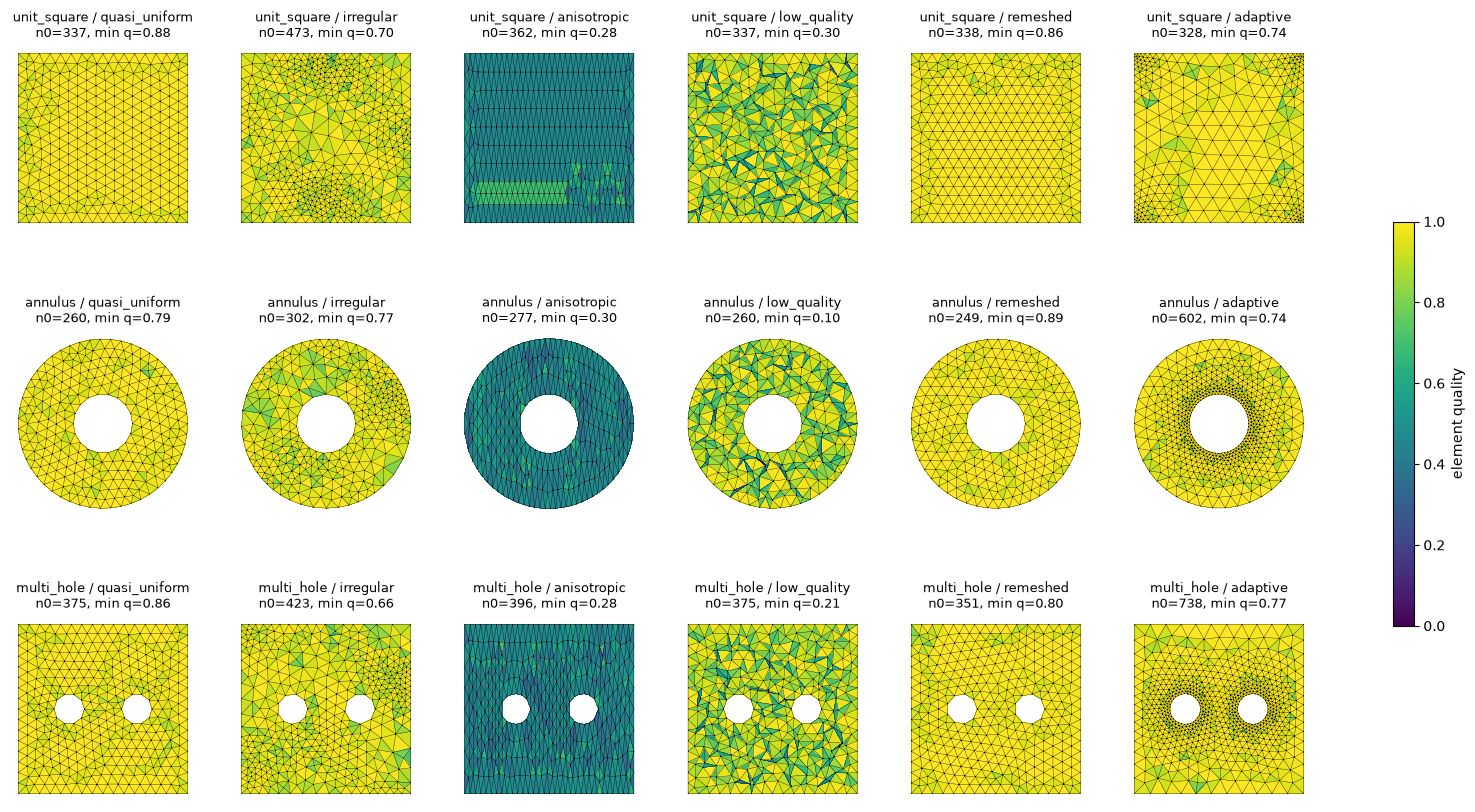

shape       regime        level        n0     n1     n2  q min  q med angle min edge max/min  AR med  AR max
unit_square quasi_uniform medium     1281   3712   2432   0.88   1.00      40.6          1.9    1.02     1.6
unit_square irregular     medium     1819   5314   3496   0.70   0.95      31.2          6.1    1.32     2.4
unit_square anisotropic   medium     1365   3932   2568   0.28   0.47      12.9          5.9    3.06     7.1
unit_square low_quality   medium     1281   3712   2432   0.30   0.89      11.3          7.4    1.58     6.5
unit_square remeshed      medium     1123   3246   2124   0.78   1.00      39.9          1.8    1.00     2.1
unit_square adaptive      medium     1225   3504   2280   0.74   0.99      36.6          8.4    1.15     2.3
annulus     quasi_uniform medium      971   2775   1804   0.79   0.99      35.0          2.2    1.14     2.0
annulus     irregular     medium     1136   3264   2128   0.66   0.95      27.1          5.4    1.32     2.5
annulus     anisotr

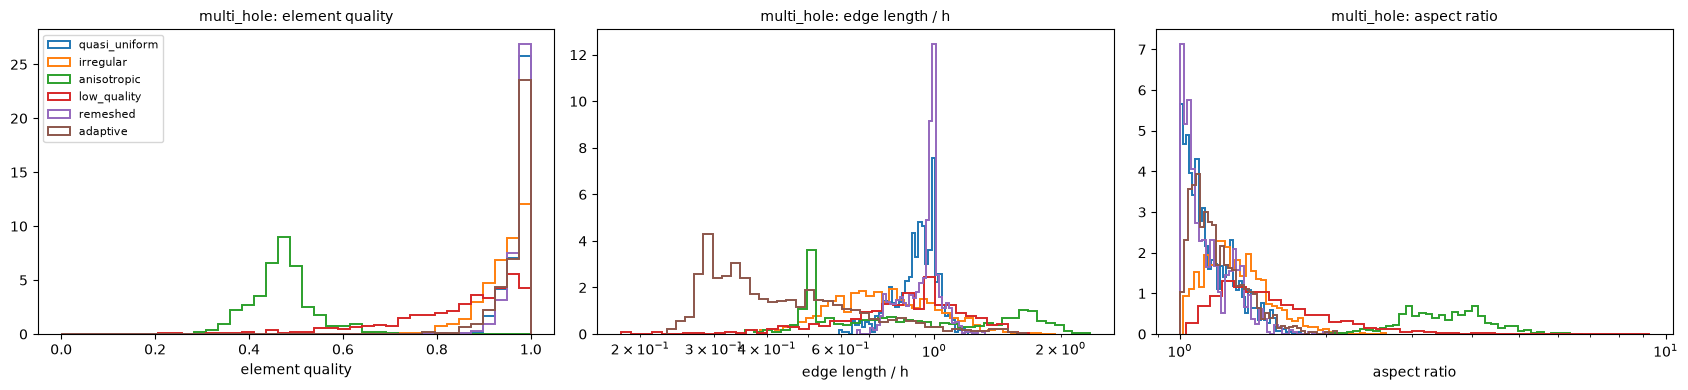

In [7]:
fig, axes = plt.subplots(3, 6, figsize=(21, 10.5))
for row, shape in zip(axes, SHAPES):
    for ax, regime in zip(row, REGIMES):
        cx = meshes[shape, regime, "coarse"][0]
        q = 4 * np.sqrt(3) * cx.area / np.sum(np.linalg.norm(cx.points[cx.tris][:, [1, 2, 0]] - cx.points[cx.tris], axis=2) ** 2, 1)
        tpc = ax.tripcolor(cx.points[:, 0], cx.points[:, 1], cx.tris, facecolors=q, cmap="viridis", vmin=0, vmax=1)
        ax.triplot(cx.points[:, 0], cx.points[:, 1], cx.tris, lw=0.25, color="k")
        ax.set_aspect("equal"); ax.axis("off")
        ax.set_title(f"{shape} / {regime}\nn0={cx.n[0]}, min q={q.min():.2f}", fontsize=9)
fig.colorbar(tpc, ax=axes, shrink=0.5, label="element quality")
save(fig, "01_mesh_gallery_quality"); plt.show()

stats = {k: mesh_stats(v[0], {"d0": v[0].d0, "d1": v[0].d1, "star0 (DEC)": runs[k + ("dec",)]["star0"],
                              "star1": v[1]["star1"], "star2": v[1]["star2"]}) for k, v in meshes.items()}
print(f"{'shape':12s}{'regime':14s}{'level':8s}{'n0':>7s}{'n1':>7s}{'n2':>7s}{'q min':>7s}{'q med':>7s}{'angle min':>10s}"
      f"{'edge max/min':>13s}{'AR med':>8s}{'AR max':>8s}")
for (shape, regime, level), s in stats.items():
    if level == "medium":
        print(f"{shape:12s}{regime:14s}{level:8s}{s['n_cells'][0]:7d}{s['n_cells'][1]:7d}{s['n_cells'][2]:7d}"
              f"{s['q'].min():7.2f}{np.median(s['q']):7.2f}{s['angle_min']:10.1f}{s['edge'].max() / s['edge'].min():13.1f}"
              f"{np.median(s['aspect']):8.2f}{s['aspect'].max():8.1f}")
print("\nsparsity (annulus, quasi_uniform, medium): nnz per row  |  density")
for k, (nnz, dens, per_row) in stats["annulus", "quasi_uniform", "medium"]["sparsity"].items():
    print(f"  {k:12s}{per_row:6.2f}   {dens:.1e}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (key, label, logx) in zip(axes, (("q", "element quality", False), ("edge", "edge length / h", True),
                                         ("aspect", "aspect ratio", True))):
    for regime in REGIMES:
        x = stats["multi_hole", regime, "coarse"][key] / (SHAPES["multi_hole"][0] if key == "edge" else 1)
        bins = np.geomspace(x.min(), x.max(), 40) if logx else np.linspace(0, 1, 40)
        ax.hist(x, bins=bins, histtype="step", lw=1.4, density=True, label=regime)
    ax.set_xscale("log" if logx else "linear"); ax.set_xlabel(label); ax.set_title(f"multi_hole: {label}", fontsize=10)
axes[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "02_quality_edge_aspect_distributions"); plt.show()

## 3. Nesting: bijections and commuting transfers

For every nested pair (5 regimes × 3 shapes × 2 steps), the following are checked:

* **cell counts:** $n_0'=n_0+n_1$, $n_1'=2n_1+3n_2$, $n_2'=4n_2$;
* **injection:** the coarse vertices reappear bit-identically as fine vertices $0..n_0-1$;
* **bijection** $V\sqcup E\to V'$: each coarse edge $(i,j)$ corresponds to the *unique* common fine neighbour of
  $i$ and $j$, and these cover exactly the new vertices;
* **orientation:** every child has its parent's orientation;
* **commuting diagram:** $d_0'P_0=P_1d_0$ and $d_1'P_1=P_2d_1$, with
  * $P_0$ linear interpolation;
  * $P_1$ Whitney interpolation: $\tfrac12$ on half-edges, $\pm\tfrac14$ on interior edges;
  * $P_2$ giving each child $\tfrac14$ of its parent.

In [8]:
def transfers(c, f):
    n0c, n0f = c.n[0], f.n[0]
    adj = sp.csr_matrix((np.ones(2 * f.n[1]), (f.edges.ravel(), f.edges[:, ::-1].ravel())), shape=(n0f, n0f))
    a, b = c.edges[:, 0], c.edges[:, 1]
    common = adj[a].multiply(adj[b]).tocsr()
    unique = bool(np.all(np.diff(common.indptr) == 1))
    mid = common.indices
    P0 = sp.csr_matrix((np.r_[np.ones(n0c), 0.5 * np.ones(2 * len(mid))], (np.r_[np.arange(n0c), mid, mid],
                                                                            np.r_[np.arange(n0c), a, b])), shape=(n0f, n0c))
    fk = f.edges[:, 0] * n0f + f.edges[:, 1]
    fo = np.argsort(fk)
    ck = c.edges[:, 0] * n0c + c.edges[:, 1]
    co = np.argsort(ck)

    def fid(u, v):
        e = np.sort(np.c_[u, v], 1)
        return fo[np.searchsorted(fk[fo], e[:, 0] * n0f + e[:, 1])]

    def cid(u, v):
        e = np.sort(np.c_[u, v], 1)
        return co[np.searchsorted(ck[co], e[:, 0] * n0c + e[:, 1])]

    sg = lambda u, v: np.where(u < v, 1.0, -1.0)  # noqa: E731
    R, Cc, V = [], [], []
    for u, v in ((a, mid), (mid, b)):
        R.append(fid(u, v)); Cc.append(np.arange(len(mid))); V.append(0.5 * sg(u, v))
    A, B, D = c.tris.T
    m_ab, m_bc, m_ca = mid[cid(A, B)], mid[cid(B, D)], mid[cid(D, A)]
    for (p, q, r), (m1, m2) in (((A, B, D), (m_ab, m_bc)), ((B, D, A), (m_bc, m_ca)), ((D, A, B), (m_ca, m_ab))):
        f_, s_ = fid(m1, m2), sg(m1, m2)
        for e, w in ((cid(p, q) * 0 + cid(p, q), 0.25 * sg(p, q)), (cid(q, r), 0.25 * sg(q, r)), (cid(r, p), -0.25 * sg(r, p))):
            R.append(f_); Cc.append(e); V.append(w * s_)
    P1 = sp.csr_matrix((np.concatenate(V), (np.concatenate(R), np.concatenate(Cc))), shape=(f.n[1], c.n[1]))
    P2 = sp.kron(sp.eye(c.n[2]), np.full((4, 1), 0.25)).tocsr()
    return P0, P1, P2, mid, unique


print(f"{'shape':12s}{'regime':14s}{'step':>6s}{'counts':>8s}{'inject':>8s}{'bijection':>10s}{'orient':>8s}"
      f"{'|d0P0-P1d0|':>13s}{'|d1P1-P2d1|':>13s}")
all_ok = True
for shape in SHAPES:
    for regime in REGIMES:
        if regime == "remeshed":
            continue
        for k in (1, 2):
            c, f = meshes[shape, regime, LEVELS[k - 1]][0], meshes[shape, regime, LEVELS[k]][0]
            counts = f.n == (c.n[0] + c.n[1], 2 * c.n[1] + 3 * c.n[2], 4 * c.n[2])
            inject = np.array_equal(f.points[: c.n[0]], c.points)
            P0, P1, P2, mid, unique = transfers(c, f)
            bij = unique and len(np.unique(mid)) == c.n[1] and set(mid) == set(range(c.n[0], f.n[0]))
            orient = np.array_equal(np.repeat(np.sign(signed_areas(c.points, c.tris)), 4), np.sign(signed_areas(f.points, f.tris)))
            e0 = abs(f.d0.astype(float) @ P0 - P1 @ c.d0.astype(float)).max()
            e1 = abs(f.d1.astype(float) @ P1 - P2 @ c.d1.astype(float)).max()
            all_ok &= counts and inject and bij and orient and e0 == 0 and e1 == 0
            print(f"{shape:12s}{regime:14s}{k:6d}{str(counts):>8s}{str(inject):>8s}{str(bij):>10s}{str(orient):>8s}"
                  f"{e0:13.1e}{e1:13.1e}")
print("\nall nesting guarantees hold exactly:", all_ok)

shape       regime          step  counts  inject bijection  orient  |d0P0-P1d0|  |d1P1-P2d1|
unit_square quasi_uniform      1    True    True      True    True      0.0e+00      0.0e+00
unit_square quasi_uniform      2    True    True      True    True      0.0e+00      0.0e+00
unit_square irregular          1    True    True      True    True      0.0e+00      0.0e+00
unit_square irregular          2    True    True      True    True      0.0e+00      0.0e+00
unit_square anisotropic        1    True    True      True    True      0.0e+00      0.0e+00
unit_square anisotropic        2    True    True      True    True      0.0e+00      0.0e+00
unit_square low_quality        1    True    True      True    True      0.0e+00      0.0e+00
unit_square low_quality        2    True    True      True    True      0.0e+00      0.0e+00
unit_square adaptive           1    True    True      True    True      0.0e+00      0.0e+00
unit_square adaptive           2    True    True      True    True    

## 4. Geometry preservation

Area and perimeter are compared with the exact CAD values, and every boundary vertex is checked for its distance
to the exact curve. Straight boundaries are reproduced exactly. Curved ones carry an $O(h^2)$ chord error, which
projection keeps converging. *Pulled back* counts the midpoints the fold safeguard kept off the circle.

shape       regime          area err coarse  area err medium    area err fine  perim err fine  max CAD dev  pulled back
unit_square quasi_uniform          0.00e+00         0.00e+00         0.00e+00        0.00e+00      0.0e+00            0
unit_square irregular              0.00e+00         0.00e+00         0.00e+00        0.00e+00      0.0e+00            0
unit_square anisotropic            0.00e+00        -1.11e-16         0.00e+00        0.00e+00      0.0e+00            0
unit_square low_quality            0.00e+00         0.00e+00         0.00e+00        0.00e+00      0.0e+00            0
unit_square remeshed               0.00e+00        -1.11e-16         0.00e+00        0.00e+00      0.0e+00            0
unit_square adaptive               0.00e+00         0.00e+00        -1.11e-16        0.00e+00      0.0e+00            0
annulus     quasi_uniform         -6.29e-05        -1.29e-05        -3.05e-06       -1.12e-04      2.2e-16            0
annulus     irregular             -1.85e

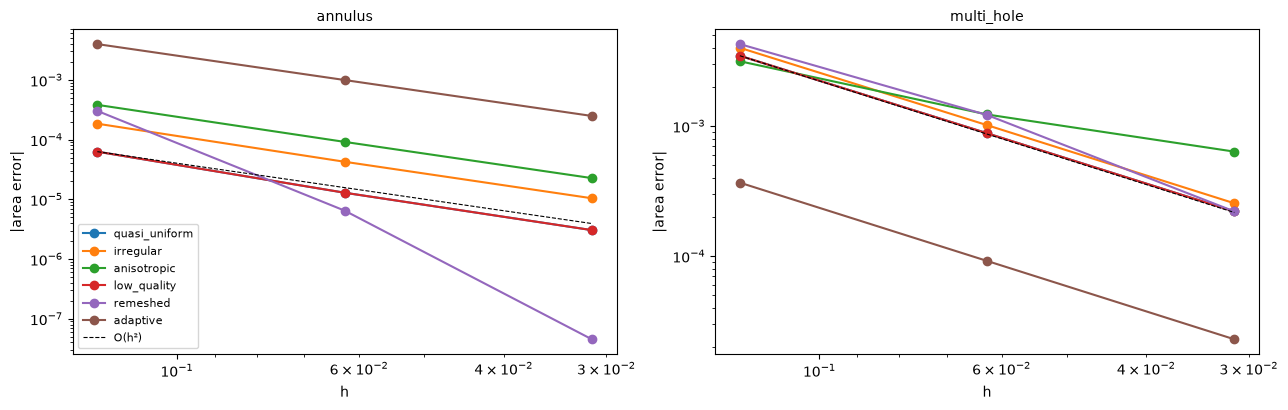

In [9]:
def cad_deviation(shape, cx):
    x, y = cx.points[cx.bverts].T
    if shape == "unit_square":
        d = [np.abs(x), np.abs(x - 1), np.abs(y), np.abs(y - 1)]
    elif shape == "annulus":
        d = [np.abs(np.hypot(x, y) - 1), np.abs(np.hypot(x, y) - 0.35)]
    else:
        d = [np.abs(np.abs(x) - 1), np.abs(np.abs(y) - 1)] + [np.abs(np.hypot(x - cx_, y) - 0.18) for cx_ in (-0.4, 0.4)]
    return float(np.min(d, axis=0).max())


geo = {}
print(f"{'shape':12s}{'regime':14s}" + "".join(f"{'area err ' + lv:>17s}" for lv in LEVELS)
      + f"{'perim err fine':>16s}{'max CAD dev':>13s}{'pulled back':>13s}")
for shape in SHAPES:
    for regime in REGIMES:
        for lv in LEVELS:
            cx = meshes[shape, regime, lv][0]
            be = cx.edges[cx.bedges]
            perim = np.linalg.norm(cx.points[be[:, 1]] - cx.points[be[:, 0]], axis=1).sum()
            geo[shape, regime, lv] = ((cx.area.sum() - SHAPES[shape][3]) / SHAPES[shape][3],
                                      (perim - SHAPES[shape][4]) / SHAPES[shape][4], cad_deviation(shape, cx))
        pulled = sum(meshes[shape, regime, lv][2]["pulled"] for lv in LEVELS)
        print(f"{shape:12s}{regime:14s}" + "".join(f"{geo[shape, regime, lv][0]:17.2e}" for lv in LEVELS)
              + f"{geo[shape, regime, 'fine'][1]:16.2e}{max(geo[shape, regime, lv][2] for lv in LEVELS):13.1e}{pulled:13d}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
hs = lambda sh: np.array([SHAPES[sh][0] / 2**k for k in range(3)])  # noqa: E731
for ax, shape in zip(axes, ("annulus", "multi_hole")):
    for regime in REGIMES:
        ax.loglog(hs(shape), [abs(geo[shape, regime, lv][0]) for lv in LEVELS], "o-", label=regime)
    ax.loglog(hs(shape), abs(geo[shape, "quasi_uniform", "coarse"][0]) * (hs(shape) / hs(shape)[0]) ** 2, "k--", lw=0.8,
              label="O(h²)")
    ax.invert_xaxis(); ax.set_xlabel("h"); ax.set_ylabel("|area error|"); ax.set_title(shape, fontsize=10)
axes[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "03_geometry_area_convergence"); plt.show()

## 5. Topology preservation

For all 54 meshes:

* $\beta_0,\beta_1$ computed from the complex must equal the analytic values;
* the number of boundary components must be $1+\beta_1$;
* $d_1d_0=0$ and the Euler characteristic must be $1-\beta_1$;
* one harmonic 1-form per hole must be constructible, **closed** ($d_1h=0$) and **co-closed** ($d_0^\top\star_1h=0$),
  giving the harmonic dimension $\beta_1$.

In [10]:
fails, worst = [], 0.0
for (shape, regime, level), (cx, st, _) in meshes.items():
    b, (nb, _) = betti(cx), boundary_components(cx)
    dd = int(abs(cx.d1.astype(int) @ cx.d0.astype(int)).max())
    H, r1, r2 = harmonic_forms(cx, st["star1"], SHAPES[shape][5])
    indep = np.linalg.matrix_rank(H.T @ (st["star1"] @ H)) == H.shape[1]
    worst = max(worst, r1, r2)
    if not (b == BETTI[shape] and nb == 1 + BETTI[shape][1] and dd == 0 and cx.n[0] - cx.n[1] + cx.n[2] == 1 - BETTI[shape][1]
            and H.shape[1] == BETTI[shape][1] and indep and max(r1, r2) < 1e-10):
        fails.append((shape, regime, level))
print(f"topology preserved on {len(meshes) - len(fails)} / {len(meshes)} meshes;"
      f" harmonic residuals (closed / co-closed) <= {worst:.1e}", fails or "")

topology preserved on 54 / 54 meshes; harmonic residuals (closed / co-closed) <= 1.9e-14 


## 6. Energy

* **Solver drift:** the exactly conserved energy of each scheme. For the DEC solver it is the staggered leapfrog
  energy with $\star_0^\text{eff}=P^{-1}$; for MFEM it is $\tfrac12\dot\phi^\top M\dot\phi+\tfrac12 u^\top\star_1u$,
  measured every step.
* **Snapshot drift:** the energy $\tfrac12p^\top\star_0p+\tfrac12u^\top\star_1u$ evaluated from the stored
  snapshots, which is what a dataset user sees.

mfem  solver drift <= 6.1e-13   snapshot drift: median 1.3e-13, max 5.7e-13
dec   solver drift <= 8.9e-16   snapshot drift: median 6.4e-04, max 9.0e-03


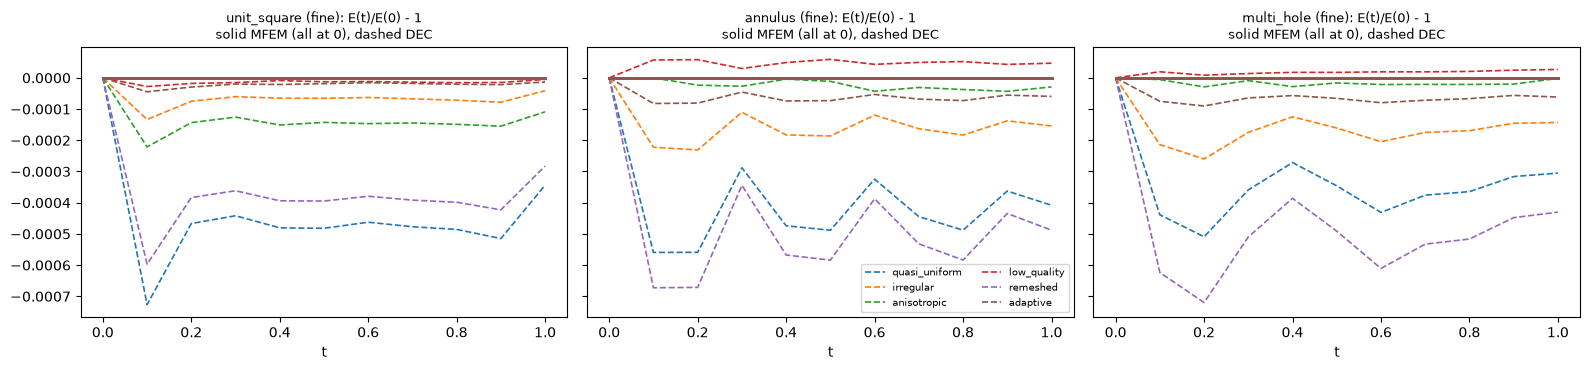

In [11]:
snap = {}
for k, r in runs.items():
    st = meshes[k[:3]][1]
    E = 0.5 * (np.einsum("ti,ti->t", r["p"], (r["star0"] @ r["p"].T).T) + np.einsum("ti,ti->t", r["u"], (st["star1"] @ r["u"].T).T))
    snap[k] = E / E[0] - 1
for solver in ("mfem", "dec"):
    d = [r["drift"] for k, r in runs.items() if k[3] == solver]
    s = [np.abs(v).max() for k, v in snap.items() if k[3] == solver]
    print(f"{solver:5s} solver drift <= {max(d):.1e}   snapshot drift: median {np.median(s):.1e}, max {max(s):.1e}")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
tt = np.linspace(0, T, NSNAP)
for ax, shape in zip(axes, SHAPES):
    for i, regime in enumerate(REGIMES):
        ax.plot(tt, snap[shape, regime, "fine", "mfem"], "-", lw=2, color=f"C{i}")
        ax.plot(tt, snap[shape, regime, "fine", "dec"], "--", lw=1.2, color=f"C{i}", label=regime)
    ax.set_title(f"{shape} (fine): E(t)/E(0) - 1\nsolid MFEM (all at 0), dashed DEC", fontsize=9); ax.set_xlabel("t")
axes[1].legend(fontsize=7, ncol=2)
fig.tight_layout(); save(fig, "04_energy_curves_fine"); plt.show()

## 7. Accuracy against an extrapolated reference

Pressure is sampled at 6 interior probe points (linear interpolation). The reference is MFEM on quasi-uniform
meshes 2× and 4× finer than the fine level, Richardson-extrapolated: $p_\text{ref}=(4p_{h/2}-p_h)/3$. Its own
error is estimated as $|p_{h/2}-p_h|/3$.

reference built in 35s; estimated error: {'unit_square': '7.9e-04', 'annulus': '2.2e-03', 'multi_hole': '7.3e-04'}



shape       regime           coarse (mfem / dec)   medium (mfem / dec)     fine (mfem / dec)
unit_square quasi_uniform        0.1786 / 0.0658       0.0511 / 0.0177       0.0127 / 0.0044
unit_square irregular            0.2638 / 0.1695       0.0778 / 0.0257       0.0220 / 0.0065
unit_square anisotropic          0.4931 / 0.2357       0.2086 / 0.0777       0.0580 / 0.0223
unit_square low_quality          0.3195 / 0.1760       0.0989 / 0.0384       0.0259 / 0.0096
unit_square remeshed             0.1856 / 0.0593       0.0596 / 0.0179       0.0107 / 0.0035
unit_square adaptive             0.4107 / 0.1931       0.1327 / 0.0305       0.0358 / 0.0077
annulus     quasi_uniform        0.2078 / 0.0649       0.0560 / 0.0215       0.0173 / 0.0077
annulus     irregular            0.2899 / 0.2762       0.0784 / 0.0591       0.0210 / 0.0166
annulus     anisotropic          0.5267 / 0.2681       0.2901 / 0.1432       0.0896 / 0.0492
annulus     low_quality          0.3263 / 0.1134       0.0977 / 0.033

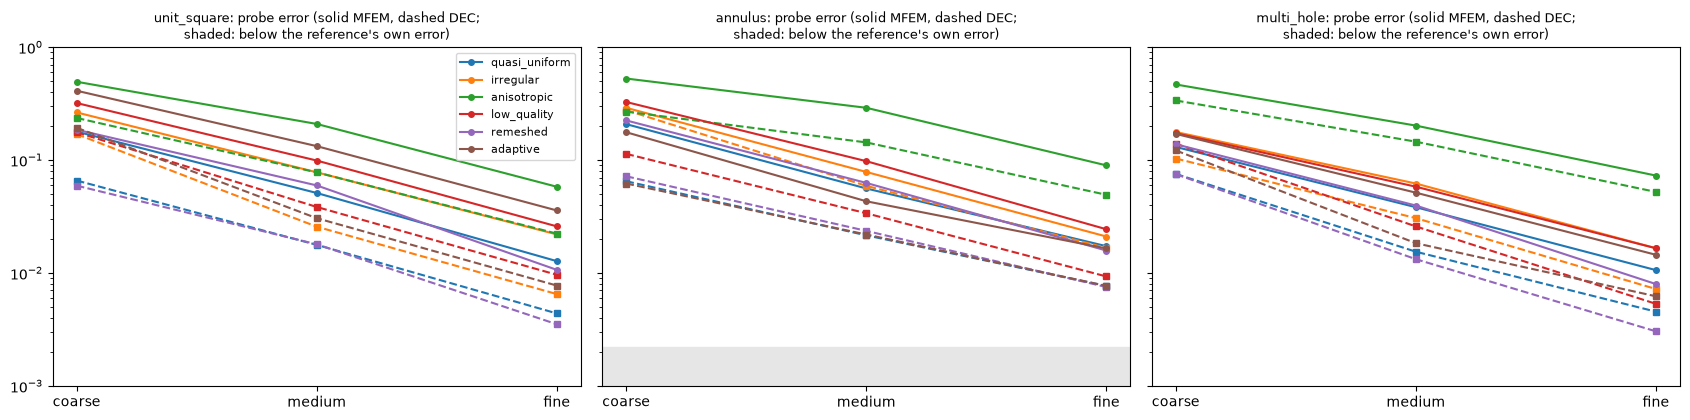

In [12]:
PROBES = {
    "unit_square": [[0.2, 0.2], [0.8, 0.3], [0.5, 0.5], [0.3, 0.8], [0.75, 0.75], [0.5, 0.15]],
    "annulus": [[r * np.cos(a), r * np.sin(a)] for r, a in ((0.6, 0.3), (0.8, 1.6), (0.55, 2.8), (0.75, 3.9), (0.6, 5.0),
                                                           (0.85, 5.9))],
    "multi_hole": [[-0.7, 0.6], [0.7, -0.6], [0.0, 0.0], [0.0, 0.7], [-0.4, -0.6], [0.65, 0.5]],
}


def probe(cx, series, shape):
    tri = mtri.Triangulation(cx.points[:, 0], cx.points[:, 1], cx.tris)
    q = np.asarray(PROBES[shape])
    return np.array([mtri.LinearTriInterpolator(tri, p)(q[:, 0], q[:, 1]).filled(np.nan) for p in series])


ref, ref_err = {}, {}
t0 = time.perf_counter()
for shape in SHAPES:
    h0, x0, w = SHAPES[shape][:3]
    p, t_, _, circles = generate(shape, h0 / 4, "quasi_uniform")
    sols = []
    for k in range(3):
        if k:
            p, t_, _ = refine(p, t_, circles)
        if k >= 1:  # levels h0/8 and h0/16
            cx = Complex(p, t_)
            sols.append(probe(cx, mfem_solve(cx, cx.stars(), np.exp(-np.sum((cx.points - x0) ** 2, axis=1) / w**2))["p"], shape))
    ref[shape] = (4 * sols[1] - sols[0]) / 3
    ref_err[shape] = np.linalg.norm(sols[1] - sols[0]) / 3 / np.linalg.norm(sols[1])
print(f"reference built in {time.perf_counter() - t0:.0f}s; estimated error:", {k: f"{v:.1e}" for k, v in ref_err.items()})

perr = {k: np.linalg.norm(probe(meshes[k[:3]][0], r["p"], k[0]) - ref[k[0]]) / np.linalg.norm(ref[k[0]])
        for k, r in runs.items()}
print(f"\n{'shape':12s}{'regime':14s}" + "".join(f"{lv + ' (mfem / dec)':>22s}" for lv in LEVELS))
for shape in SHAPES:
    for regime in REGIMES:
        print(f"{shape:12s}{regime:14s}" + "".join(f"{perr[shape, regime, lv, 'mfem']:13.4f} /{perr[shape, regime, lv, 'dec']:7.4f}"
                                              for lv in LEVELS))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), sharey=True)
for ax, shape in zip(axes, SHAPES):
    ax.axhspan(1e-4, ref_err[shape], color="0.9")
    for i, regime in enumerate(REGIMES):
        for solver, ls, mk in (("mfem", "-", "o"), ("dec", "--", "s")):
            ax.semilogy(range(3), [perr[shape, regime, lv, solver] for lv in LEVELS], ls, marker=mk, color=f"C{i}", ms=4,
                        label=regime if solver == "mfem" else None)
    ax.set_xticks(range(3)); ax.set_xticklabels(LEVELS); ax.set_ylim(1e-3, 1)
    ax.set_title(f"{shape}: probe error (solid MFEM, dashed DEC;\nshaded: below the reference's own error)", fontsize=9)
axes[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "05_probe_error_vs_resolution"); plt.show()

## 8. Cost

shape       regime         DEC steps   DEC s MFEM steps  MFEM s   (fine level, per snapshot interval)
unit_square quasi_uniform         19    0.04         19    0.25
unit_square irregular             38    0.08         38    0.83
unit_square anisotropic           32    0.05         32    0.45
unit_square low_quality           53    0.06         53    0.80
unit_square remeshed              21    0.05         21    0.31
unit_square adaptive              55    0.06         55    0.77
annulus     quasi_uniform         12    0.04         12    0.19
annulus     irregular             17    0.03         17    0.25
annulus     anisotropic           25    0.06         18    0.47
annulus     low_quality           61    0.06         25    0.28
annulus     remeshed              11    0.03         11    0.15
annulus     adaptive              30    0.08         30    0.83
multi_hole  quasi_uniform         13    0.03         13    0.20
multi_hole  irregular             17    0.04         17    0.32
mu

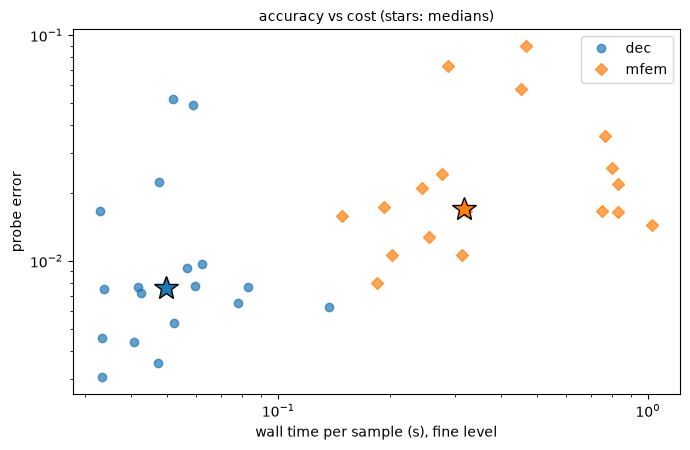

In [13]:
print(f"{'shape':12s}{'regime':14s}{'DEC steps':>10s}{'DEC s':>8s}{'MFEM steps':>11s}{'MFEM s':>8s}   (fine level, per snapshot interval)")
for shape in SHAPES:
    for regime in REGIMES:
        a, b = runs[shape, regime, "fine", "dec"], runs[shape, regime, "fine", "mfem"]
        print(f"{shape:12s}{regime:14s}{a['steps']:10d}{wall[shape, regime, 'fine', 'dec']:8.2f}{b['steps']:11d}"
              f"{wall[shape, regime, 'fine', 'mfem']:8.2f}")

fig, ax = plt.subplots(figsize=(7, 4.6))
for solver, mk in (("dec", "o"), ("mfem", "D")):
    e = [perr[k] for k in perr if k[3] == solver and k[2] == "fine"]
    w_ = [wall[k] for k in perr if k[3] == solver and k[2] == "fine"]
    ax.loglog(w_, e, mk, alpha=0.7, label=solver)
    ax.loglog(np.median(w_), np.median(e), "*", ms=18, mec="k", color="C0" if solver == "dec" else "C1")
ax.set_xlabel("wall time per sample (s), fine level"); ax.set_ylabel("probe error"); ax.legend()
ax.set_title("accuracy vs cost (stars: medians)", fontsize=10)
fig.tight_layout(); save(fig, "06_accuracy_vs_cost"); plt.show()

## 9. Findings (recomputed from the runs above)

In [14]:
curved = ["annulus", "multi_hole"]
print("NESTING     all bijection / injection / orientation / commuting-diagram checks exact:", all_ok)
print("GEOMETRY    max boundary-vertex distance to the CAD (excluding pulled-back vertices):",
      f"{max(g[2] for (s, r, l), g in geo.items() if not (r == 'anisotropic' and s == 'multi_hole')):.1e};",
      "fine-level area error (curved shapes): " + ", ".join(f"{r} {max(abs(geo[s, r, 'fine'][0]) for s in curved):.1e}" for r in REGIMES))
print(f"TOPOLOGY    preserved on {len(meshes) - len(fails)} / {len(meshes)} meshes")
for solver in ("mfem", "dec"):
    print(f"ENERGY      {solver:5s} solver drift <= {max(r['drift'] for k, r in runs.items() if k[3] == solver):.0e}")
for solver in ("mfem", "dec"):
    e = [perr[s, r, "fine", solver] for s in SHAPES for r in REGIMES]
    w_ = [wall[s, r, "fine", solver] for s in SHAPES for r in REGIMES]
    print(f"ACCURACY    {solver:5s} fine-level probe error median {np.median(e):.4f}, worst {max(e):.4f}; "
          f"median wall {np.median(w_):.2f}s")
print("COST        DEC steps relative to quasi-uniform (fine): " + ", ".join(
    f"{r} x{np.mean([runs[s, r, 'fine', 'dec']['steps'] / runs[s, 'quasi_uniform', 'fine', 'dec']['steps'] for s in SHAPES]):.1f}"
    for r in REGIMES))

NESTING     all bijection / injection / orientation / commuting-diagram checks exact: True
GEOMETRY    max boundary-vertex distance to the CAD (excluding pulled-back vertices): 2.2e-16; fine-level area error (curved shapes): quasi_uniform 2.2e-04, irregular 2.5e-04, anisotropic 6.3e-04, low_quality 2.2e-04, remeshed 2.2e-04, adaptive 2.5e-04
TOPOLOGY    preserved on 54 / 54 meshes
ENERGY      mfem  solver drift <= 6e-13
ENERGY      dec   solver drift <= 9e-16
ACCURACY    mfem  fine-level probe error median 0.0169, worst 0.0896; median wall 0.32s
ACCURACY    dec   fine-level probe error median 0.0076, worst 0.0522; median wall 0.05s
COST        DEC steps relative to quasi-uniform (fine): quasi_uniform x1.0, irregular x1.6, anisotropic x2.2, low_quality x3.5, remeshed x1.0, adaptive x2.5
